In [ ]:
!pip install scikit-learn pandas -q

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


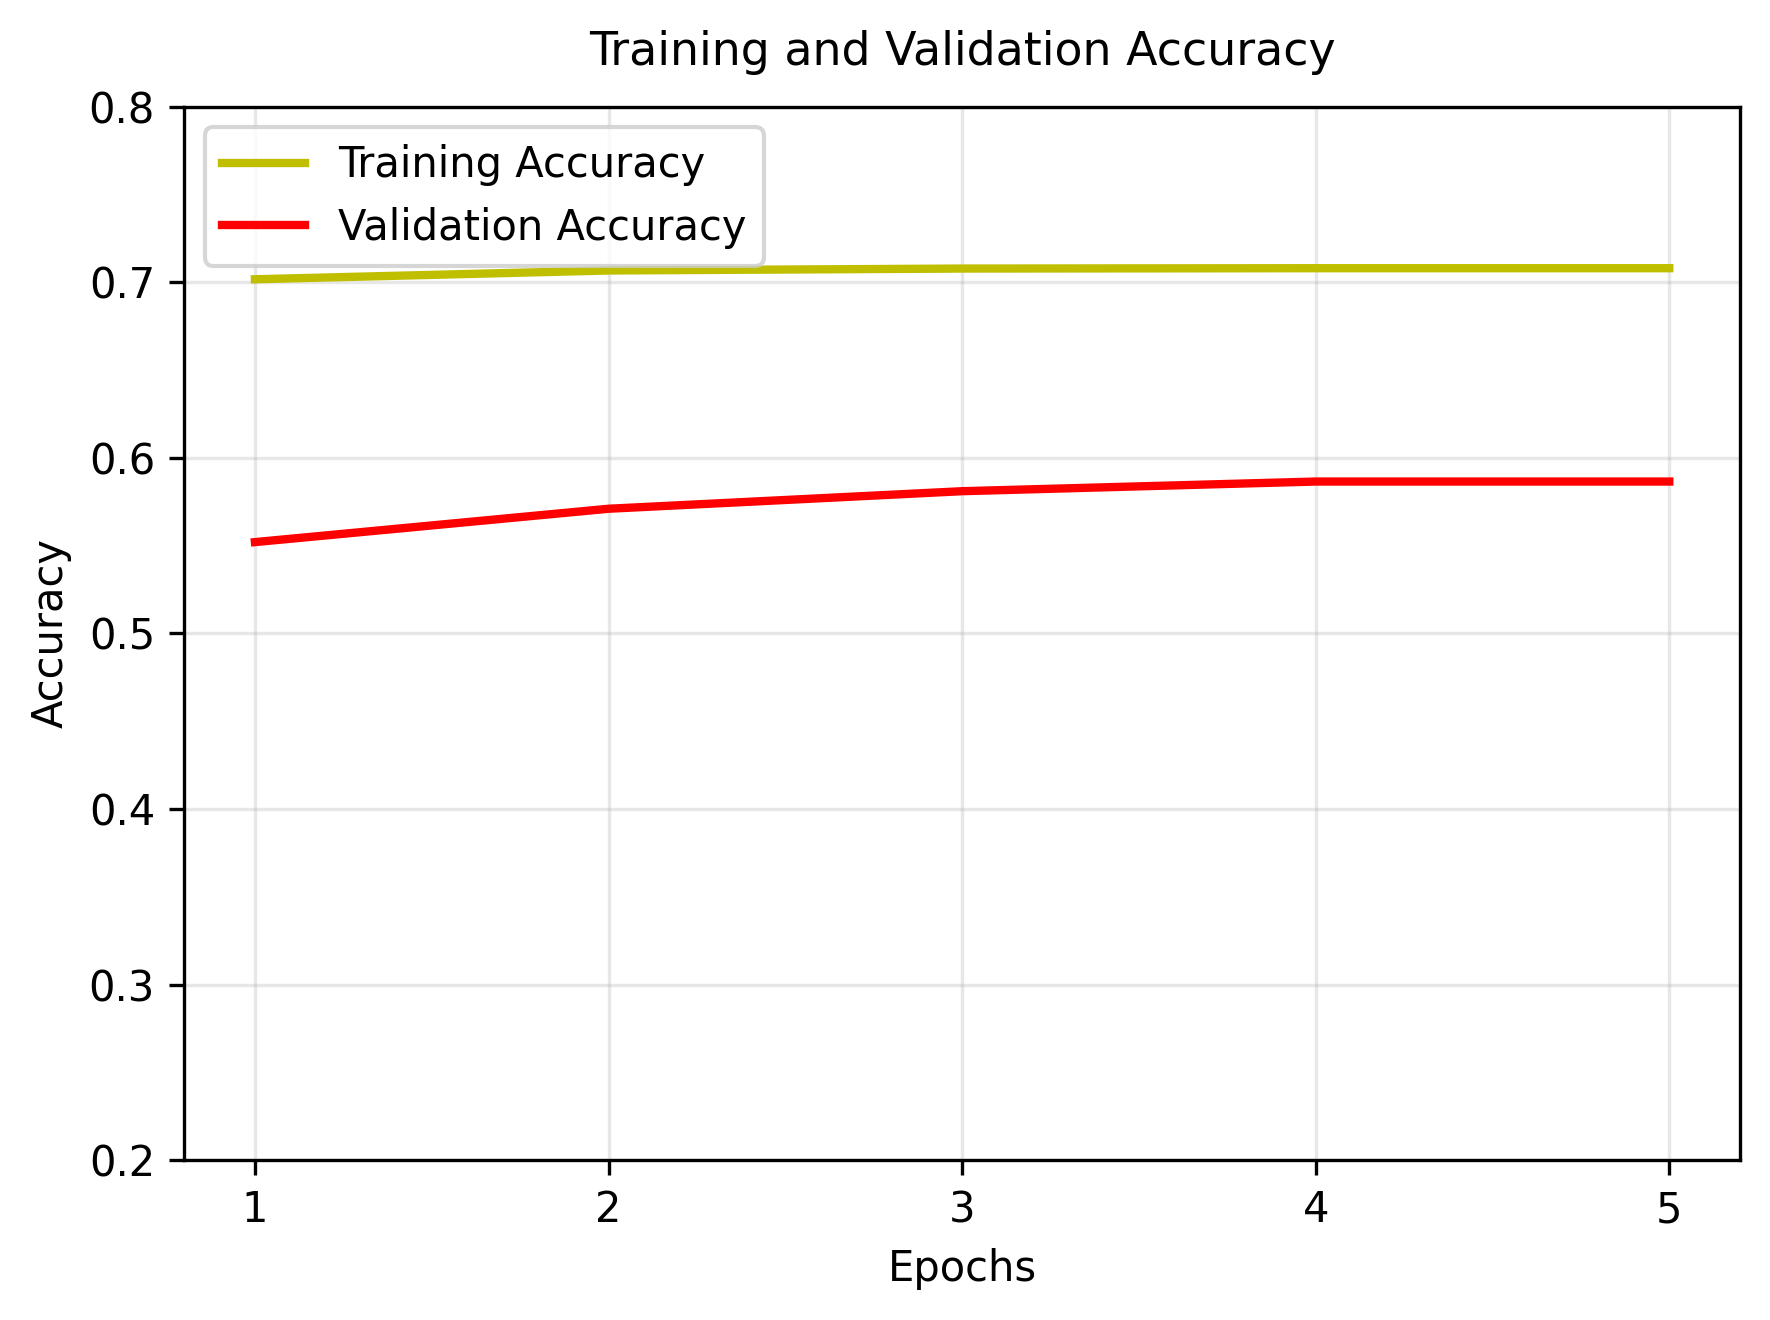

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Generations (Epochs)
generations = np.array([1, 2, 3, 4, 5])

# Performance data from your Colab notebook
phone_train_acc = np.array([0.7017, 0.7067, 0.7078, 0.7080, 0.7080])
phone_val_acc   = np.array([0.5520, 0.5710, 0.5810, 0.5865, 0.5865])

# Plot setup matching sample image layout
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=300)
ax.plot(generations, phone_train_acc, color='y', label='Training Accuracy', linewidth=2)
ax.plot(generations, phone_val_acc, color='r', label='Validation Accuracy', linewidth=2)

ax.set_title('Training and Validation Accuracy', fontsize=11, fontweight='normal', pad=10)
ax.set_xlabel('Epochs', fontsize=10)
ax.set_ylabel('Accuracy', fontsize=10)
ax.set_xticks(generations)
ax.set_ylim(0.2, 0.8)
ax.legend(loc='upper left', frameon=True)
ax.grid(True, linestyle='-', alpha=0.3)

plt.tight_layout()
plt.savefig('report_accuracy_plot_phone.png', dpi=300)
plt.show()

In [ ]:
folder = '/content/drive/MyDrive/ml'

phone_df = pd.read_csv(f'{folder}/domain1.csv')
imdb_df = pd.read_csv(f'{folder}/domain2.csv')
yelp_df = pd.read_csv(f'{folder}/domain3.csv')

print("Phone dataset shape:", phone_df.shape)
print("IMDB dataset shape:", imdb_df.shape)
print("Yelp dataset shape:", yelp_df.shape)

Phone dataset shape: (50000, 3)
IMDB dataset shape: (50000, 2)
Yelp dataset shape: (19896, 4)


In [ ]:
print("Phone columns:")
print(phone_df.columns.tolist())

print("\nIMDB columns:")
print(imdb_df.columns.tolist())

print("\nYelp columns:")
print(yelp_df.columns.tolist())

Phone columns:
['sentiment', 'text', 'label']

IMDB columns:
['review', 'sentiment']

Yelp columns:
['Yelp URL', 'Rating', 'Date', 'Review Text']


In [ ]:
phone_domain = phone_df[['text', 'label']].copy()

phone_domain = phone_domain.dropna()

phone_domain['text'] = phone_domain['text'].astype(str)
phone_domain['label'] = phone_domain['label'].astype(int)

phone_domain['domain'] = 'phone_reviews'

print(phone_domain.head())
print("\nPhone shape:", phone_domain.shape)

                                                text  label         domain
0  good mobile. battery is 5000 mah is very big. ...      2  phone_reviews
1  Overall in hand ecpirience is quite good matt ...      2  phone_reviews
2  1. Superb Camera,\n2. No lag\n3. This is my fi...      2  phone_reviews
3  Bigger size of application names doesn't allow...      2  phone_reviews
4  Just a hype of stock android which is not flaw...      0  phone_reviews

Phone shape: (49997, 3)


In [ ]:
imdb_domain = imdb_df[['review', 'sentiment']].copy()

imdb_domain = imdb_domain.rename(
    columns={
        'review': 'text',
        'sentiment': 'label'
    }
)

imdb_domain = imdb_domain.dropna()

imdb_domain['text'] = imdb_domain['text'].astype(str)

imdb_domain['label'] = imdb_domain['label'].map({
    'negative': 0,
    'positive': 2
})

imdb_domain['domain'] = 'movie_reviews'

print(imdb_domain.head())
print("\nIMDB shape:", imdb_domain.shape)

                                                text  label         domain
0  One of the other reviewers has mentioned that ...      2  movie_reviews
1  A wonderful little production. <br /><br />The...      2  movie_reviews
2  I thought this was a wonderful way to spend ti...      2  movie_reviews
3  Basically there's a family where a little boy ...      0  movie_reviews
4  Petter Mattei's "Love in the Time of Money" is...      2  movie_reviews

IMDB shape: (50000, 3)


In [ ]:
def bucket_stars(rating):
    if rating <= 2:
        return 0
    elif rating == 3:
        return 1
    else:
        return 2


yelp_df['bucketed_label'] = yelp_df['Rating'].apply(bucket_stars)

yelp_domain = yelp_df[['Review Text', 'bucketed_label']].copy()

yelp_domain = yelp_domain.rename(
    columns={
        'Review Text': 'text',
        'bucketed_label': 'label'
    }
)

yelp_domain = yelp_domain.dropna()

yelp_domain['text'] = yelp_domain['text'].astype(str)
yelp_domain['label'] = yelp_domain['label'].astype(int)

yelp_domain['domain'] = 'restaurant_reviews'

print(yelp_domain.head())
print("\nYelp shape:", yelp_domain.shape)

                                                text  label  \
0  All I can say is they have very good ice cream...      2   
1  Nice little local place for ice cream.My favor...      2   
2  A delicious treat on a hot day! Staff was very...      2   
3  This was great service and a fun crew! I got t...      2   
4  This is one of my favorite places to get ice c...      2   

               domain  
0  restaurant_reviews  
1  restaurant_reviews  
2  restaurant_reviews  
3  restaurant_reviews  
4  restaurant_reviews  

Yelp shape: (19896, 3)


In [ ]:
all_data = pd.concat(
    [
        phone_domain,
        imdb_domain,
        yelp_domain
    ],
    ignore_index=True
)

print("Combined dataset shape:", all_data.shape)

print("\nDomain counts:")
print(all_data['domain'].value_counts())

print("\nLabel counts:")
print(all_data['label'].value_counts())

Combined dataset shape: (119893, 3)

Domain counts:
domain
movie_reviews         50000
phone_reviews         49997
restaurant_reviews    19896
Name: count, dtype: int64

Label counts:
label
2    66509
0    41660
1    11724
Name: count, dtype: int64


In [ ]:
print(
    all_data.groupby(['domain', 'label']).size()
)

domain              label
movie_reviews       0        25000
                    2        25000
phone_reviews       0        14163
                    1         9655
                    2        26179
restaurant_reviews  0         2497
                    1         2069
                    2        15330
dtype: int64


In [ ]:
output_path = '/content/drive/MyDrive/ml/all_data_combined.csv'

all_data.to_csv(output_path, index=False)

print("Combined dataset saved to:")
print(output_path)

Combined dataset saved to:
/content/drive/MyDrive/ml/all_data_combined.csv


In [ ]:
def split_domain(df, domain_name):
    subset = df[df['domain'] == domain_name]

    X_train, X_test, y_train, y_test = train_test_split(
        subset['text'],
        subset['label'],
        test_size=0.2,
        random_state=42,
        stratify=subset['label']
    )

    return X_train, X_test, y_train, y_test


phone_split = split_domain(
    all_data,
    'phone_reviews'
)

movie_split = split_domain(
    all_data,
    'movie_reviews'
)

restaurant_split = split_domain(
    all_data,
    'restaurant_reviews'
)

print("Phone train size:", len(phone_split[0]))
print("Phone test size:", len(phone_split[1]))

print("\nMovie train size:", len(movie_split[0]))
print("Movie test size:", len(movie_split[1]))

print("\nRestaurant train size:", len(restaurant_split[0]))
print("Restaurant test size:", len(restaurant_split[1]))


Phone train size: 39997
Phone test size: 10000

Movie train size: 40000
Movie test size: 10000

Restaurant train size: 15916
Restaurant test size: 3980


In [ ]:
def evaluate_template(
    ngram_range,
    vectorizer_type,
    use_stopwords,
    max_features,
    X_train,
    X_test,
    y_train,
    y_test
):

    if vectorizer_type == 'tfidf':

        vec = TfidfVectorizer(
            ngram_range=ngram_range,
            stop_words='english' if use_stopwords else None,
            max_features=max_features
        )

    else:

        vec = CountVectorizer(
            ngram_range=ngram_range,
            stop_words='english' if use_stopwords else None,
            max_features=max_features
        )

    X_train_vec = vec.fit_transform(X_train)
    X_test_vec = vec.transform(X_test)

    clf = LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    )

    clf.fit(X_train_vec, y_train)

    y_pred = clf.predict(X_test_vec)

    acc = accuracy_score(y_test, y_pred)

    f1_macro = f1_score(
        y_test,
        y_pred,
        average='macro'
    )

    return acc, f1_macro

In [ ]:
acc, f1 = evaluate_template(
    ngram_range=(1, 1),
    vectorizer_type='tfidf',
    use_stopwords=False,
    max_features=5000,
    X_train=phone_split[0],
    X_test=phone_split[1],
    y_train=phone_split[2],
    y_test=phone_split[3]
)

print("Phone domain")
print("Accuracy:", acc)
print("Macro F1:", f1)

Phone domain
Accuracy: 0.7092
Macro F1: 0.6665252078765777


In [ ]:
import random

In [ ]:
VECTOR_TYPES = [
    'count',
    'tfidf'
]

NGRAMS = [
    (1, 1),
    (1, 2),
    (1, 3)
]

STOPWORDS = [
    False,
    True
]

MAX_FEATURES = [
    3000,
    5000,
    10000
]

POPULATION_SIZE = 8
GENERATIONS = 5
MUTATION_RATE = 0.20

RANDOM_SEED = 42

random.seed(RANDOM_SEED)

print("Vectorizer options:", VECTOR_TYPES)
print("N-gram options:", NGRAMS)
print("Stopword options:", STOPWORDS)
print("Max feature options:", MAX_FEATURES)

Vectorizer options: ['count', 'tfidf']
N-gram options: [(1, 1), (1, 2), (1, 3)]
Stopword options: [False, True]
Max feature options: [3000, 5000, 10000]


In [ ]:
def random_individual():

    return [
        random.randint(0, len(VECTOR_TYPES) - 1),
        random.randint(0, len(NGRAMS) - 1),
        random.randint(0, len(STOPWORDS) - 1),
        random.randint(0, len(MAX_FEATURES) - 1)
    ]

In [ ]:
def decode_individual(individual):

    vectorizer_type = VECTOR_TYPES[individual[0]]

    ngram_range = NGRAMS[individual[1]]

    use_stopwords = STOPWORDS[individual[2]]

    max_features = MAX_FEATURES[individual[3]]

    return (
        ngram_range,
        vectorizer_type,
        use_stopwords,
        max_features
    )

In [ ]:
test_individual = random_individual()

print("Chromosome:")
print(test_individual)

print("\nDecoded configuration:")
print(decode_individual(test_individual))

Chromosome:
[0, 0, 1, 0]

Decoded configuration:
((1, 1), 'count', True, 3000)


In [ ]:
def fitness(
    individual,
    X_train,
    X_test,
    y_train,
    y_test
):

    (
        ngram_range,
        vectorizer_type,
        use_stopwords,
        max_features
    ) = decode_individual(individual)

    try:

        acc, f1_macro = evaluate_template(
            ngram_range=ngram_range,
            vectorizer_type=vectorizer_type,
            use_stopwords=use_stopwords,
            max_features=max_features,
            X_train=X_train,
            X_test=X_test,
            y_train=y_train,
            y_test=y_test
        )

        return f1_macro, acc

    except Exception as e:

        print("Error:", e)

        return 0, 0

In [ ]:
def tournament_selection(
    population,
    scores,
    tournament_size=3
):

    selected_indices = random.sample(
        range(len(population)),
        tournament_size
    )

    best_index = max(
        selected_indices,
        key=lambda i: scores[i][0]
    )

    return population[best_index][:]

In [ ]:
def crossover(parent1, parent2):

    point = random.randint(
        1,
        len(parent1) - 1
    )

    child1 = (
        parent1[:point] +
        parent2[point:]
    )

    child2 = (
        parent2[:point] +
        parent1[point:]
    )

    return child1, child2

In [ ]:
def mutate(individual):

    individual = individual[:]

    if random.random() < MUTATION_RATE:

        gene = random.randint(
            0,
            len(individual) - 1
        )

        if gene == 0:

            individual[gene] = random.randint(
                0,
                len(VECTOR_TYPES) - 1
            )

        elif gene == 1:

            individual[gene] = random.randint(
                0,
                len(NGRAMS) - 1
            )

        elif gene == 2:

            individual[gene] = random.randint(
                0,
                len(STOPWORDS) - 1
            )

        elif gene == 3:

            individual[gene] = random.randint(
                0,
                len(MAX_FEATURES) - 1
            )

    return individual

In [ ]:
def run_genetic_algorithm(
    domain_name,
    split_data
):

    X_train, X_test, y_train, y_test = split_data

    print("=" * 60)
    print("Running Genetic Algorithm for:", domain_name)
    print("=" * 60)

    population = [
        random_individual()
        for _ in range(POPULATION_SIZE)
    ]

    best_individual = None
    best_f1 = -1
    best_accuracy = 0

    for generation in range(GENERATIONS):

        print("\nGeneration", generation + 1)

        scores = []

        for individual in population:

            f1, acc = fitness(
                individual,
                X_train,
                X_test,
                y_train,
                y_test
            )

            scores.append(
                (f1, acc)
            )

            if f1 > best_f1:

                best_f1 = f1
                best_accuracy = acc
                best_individual = individual[:]

        ranked = sorted(
            zip(population, scores),
            key=lambda x: x[1][0],
            reverse=True
        )

        print("\nTop 3 individuals:")

        for rank, (individual, score) in enumerate(
            ranked[:3],
            start=1
        ):

            print(
                rank,
                individual,
                "F1 =", round(score[0], 4),
                "Accuracy =", round(score[1], 4)
            )

        # Keep the best two individuals
        new_population = [
            ranked[0][0][:],
            ranked[1][0][:]
        ]

        while len(new_population) < POPULATION_SIZE:

            parent1 = tournament_selection(
                population,
                scores
            )

            parent2 = tournament_selection(
                population,
                scores
            )

            child1, child2 = crossover(
                parent1,
                parent2
            )

            child1 = mutate(child1)
            child2 = mutate(child2)

            new_population.append(child1)

            if len(new_population) < POPULATION_SIZE:
                new_population.append(child2)

        population = new_population

    best_config = decode_individual(
        best_individual
    )

    print("\n" + "=" * 60)
    print("BEST RESULT FOR", domain_name)
    print("=" * 60)

    print("Best chromosome:", best_individual)

    print("Best configuration:")

    print(
        "N-gram:",
        best_config[0]
    )

    print(
        "Vectorizer:",
        best_config[1]
    )

    print(
        "Stopwords:",
        best_config[2]
    )

    print(
        "Max features:",
        best_config[3]
    )

    print(
        "Accuracy:",
        round(best_accuracy, 4)
    )

    print(
        "Macro F1:",
        round(best_f1, 4)
    )

    return {
        'domain': domain_name,
        'chromosome': best_individual,
        'ngram_range': best_config[0],
        'vectorizer': best_config[1],
        'stopwords': best_config[2],
        'max_features': best_config[3],
        'accuracy': best_accuracy,
        'macro_f1': best_f1
    }

In [ ]:
phone_ga_result = run_genetic_algorithm(
    'phone_reviews',
    phone_split
)

Running Genetic Algorithm for: phone_reviews

Generation 1

Top 3 individuals:
1 [1, 0, 0, 2] F1 = 0.6641 Accuracy = 0.7078
2 [0, 2, 0, 2] F1 = 0.6576 Accuracy = 0.7067
3 [0, 0, 0, 0] F1 = 0.656 Accuracy = 0.7017

Generation 2

Top 3 individuals:
1 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708
2 [1, 0, 0, 2] F1 = 0.6641 Accuracy = 0.7078
3 [1, 0, 0, 2] F1 = 0.6641 Accuracy = 0.7078

Generation 3

Top 3 individuals:
1 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708
2 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708
3 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708

Generation 4

Top 3 individuals:
1 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708
2 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708
3 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708

Generation 5

Top 3 individuals:
1 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708
2 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708
3 [1, 0, 0, 0] F1 = 0.6659 Accuracy = 0.708

BEST RESULT FOR phone_reviews
Best chromosome: [1, 0, 0, 0]
Best configuration:
N-gram: (1, 1)
Vectorizer: tfidf
Stopwor

In [ ]:
movie_ga_result = run_genetic_algorithm(
    'movie_reviews',
    movie_split
)

Running Genetic Algorithm for: movie_reviews

Generation 1

Top 3 individuals:
1 [0, 0, 0, 2] F1 = 0.8837 Accuracy = 0.8837
2 [1, 1, 1, 0] F1 = 0.8823 Accuracy = 0.8823
3 [0, 0, 0, 1] F1 = 0.8795 Accuracy = 0.8795

Generation 2

Top 3 individuals:
1 [1, 1, 0, 0] F1 = 0.8883 Accuracy = 0.8883
2 [0, 0, 0, 2] F1 = 0.8837 Accuracy = 0.8837
3 [0, 0, 0, 2] F1 = 0.8837 Accuracy = 0.8837

Generation 3

Top 3 individuals:
1 [1, 0, 0, 2] F1 = 0.8985 Accuracy = 0.8985
2 [1, 1, 0, 0] F1 = 0.8883 Accuracy = 0.8883
3 [1, 1, 0, 0] F1 = 0.8883 Accuracy = 0.8883

Generation 4

Top 3 individuals:
1 [1, 0, 0, 2] F1 = 0.8985 Accuracy = 0.8985
2 [1, 0, 0, 2] F1 = 0.8985 Accuracy = 0.8985
3 [1, 0, 0, 2] F1 = 0.8985 Accuracy = 0.8985

Generation 5

Top 3 individuals:
1 [1, 0, 0, 2] F1 = 0.8985 Accuracy = 0.8985
2 [1, 0, 0, 2] F1 = 0.8985 Accuracy = 0.8985
3 [1, 0, 0, 2] F1 = 0.8985 Accuracy = 0.8985

BEST RESULT FOR movie_reviews
Best chromosome: [1, 0, 0, 2]
Best configuration:
N-gram: (1, 1)
Vectorizer: tf

In [ ]:
restaurant_ga_result = run_genetic_algorithm(
    'restaurant_reviews',
    restaurant_split
)

Running Genetic Algorithm for: restaurant_reviews

Generation 1

Top 3 individuals:
1 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364
2 [1, 1, 0, 0] F1 = 0.7017 Accuracy = 0.8294
3 [1, 1, 0, 0] F1 = 0.7017 Accuracy = 0.8294

Generation 2

Top 3 individuals:
1 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364
2 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364
3 [1, 1, 0, 0] F1 = 0.7017 Accuracy = 0.8294

Generation 3

Top 3 individuals:
1 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364
2 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364
3 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364

Generation 4

Top 3 individuals:
1 [1, 1, 0, 2] F1 = 0.7207 Accuracy = 0.8465
2 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364
3 [1, 1, 0, 1] F1 = 0.7121 Accuracy = 0.8364

Generation 5

Top 3 individuals:
1 [1, 1, 0, 2] F1 = 0.7207 Accuracy = 0.8465
2 [1, 1, 0, 2] F1 = 0.7207 Accuracy = 0.8465
3 [1, 1, 0, 2] F1 = 0.7207 Accuracy = 0.8465

BEST RESULT FOR restaurant_reviews
Best chromosome: [1, 1, 0, 2]
Best configuration:
N-gram: (1, 2)
Vect

In [ ]:
ga_results = pd.DataFrame([
    phone_ga_result,
    movie_ga_result,
    restaurant_ga_result
])

ga_results

,domain,chromosome,ngram_range,vectorizer,stopwords,max_features,accuracy,macro_f1
0,phone_reviews,"[1, 0, 0, 0]","(1, 1)",tfidf,False,3000,0.708000,0.665882
1,movie_reviews,"[1, 0, 0, 2]","(1, 1)",tfidf,False,10000,0.898500,0.898497
2,restaurant_reviews,"[1, 1, 0, 2]","(1, 2)",tfidf,False,10000,0.846482,0.720738


In [ ]:
ga_output_path = '/content/drive/MyDrive/ml/ga_results.csv'

ga_results.to_csv(
    ga_output_path,
    index=False
)

print("GA results saved to:")
print(ga_output_path)

GA results saved to:
/content/drive/MyDrive/ml/ga_results.csv


In [ ]:
def build_crossdomain_split(all_data, holdout_domain):
    train_domains_df = all_data[all_data['domain'] != holdout_domain]

    X_train, X_test, y_train, y_test = train_test_split(
        train_domains_df['text'],
        train_domains_df['label'],
        test_size=0.2,
        random_state=42,
        stratify=train_domains_df['label']
    )

    holdout_df = all_data[all_data['domain'] == holdout_domain]
    X_holdout = holdout_df['text']
    y_holdout = holdout_df['label']

    return X_train, X_test, y_train, y_test, X_holdout, y_holdout

In [ ]:
X_train, X_test, y_train, y_test, X_holdout, y_holdout = build_crossdomain_split(
    all_data, holdout_domain='restaurant_reviews'
)

print("Generalist train size:", len(X_train))
print("Generalist test size:", len(X_test))
print("Held-out (restaurant) size:", len(X_holdout))

Generalist train size: 79997
Generalist test size: 20000
Held-out (restaurant) size: 19896


In [ ]:
generalist_ga_result = run_genetic_algorithm(
    'generalist_excl_restaurant',
    (X_train, X_test, y_train, y_test)
)

Running Genetic Algorithm for: generalist_excl_restaurant

Generation 1

Top 3 individuals:
1 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
2 [1, 1, 1, 2] F1 = 0.6916 Accuracy = 0.756
3 [1, 1, 1, 2] F1 = 0.6916 Accuracy = 0.756

Generation 2

Top 3 individuals:
1 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
2 [1, 2, 1, 2] F1 = 0.6923 Accuracy = 0.7568
3 [1, 1, 1, 2] F1 = 0.6916 Accuracy = 0.756

Generation 3

Top 3 individuals:
1 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
2 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
3 [1, 2, 1, 2] F1 = 0.6923 Accuracy = 0.7568

Generation 4

Top 3 individuals:
1 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
2 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
3 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613

Generation 5

Top 3 individuals:
1 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
2 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613
3 [1, 2, 0, 1] F1 = 0.697 Accuracy = 0.7613

BEST RESULT FOR generalist_excl_restaurant
Best chromosome: [1, 2, 0, 1]
Best configuration:
N-gram: (1, 3)
V

In [ ]:
def evaluate_on_holdout(best_result, X_train, y_train, X_holdout, y_holdout):
    ngram_range = best_result['ngram_range']
    vectorizer_type = best_result['vectorizer']
    use_stopwords = best_result['stopwords']
    max_features = best_result['max_features']

    if vectorizer_type == 'tfidf':
        vec = TfidfVectorizer(
            ngram_range=ngram_range,
            stop_words='english' if use_stopwords else None,
            max_features=max_features
        )
    else:
        vec = CountVectorizer(
            ngram_range=ngram_range,
            stop_words='english' if use_stopwords else None,
            max_features=max_features
        )

    X_train_vec = vec.fit_transform(X_train)
    X_holdout_vec = vec.transform(X_holdout)

    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_train_vec, y_train)

    y_pred = clf.predict(X_holdout_vec)

    acc = accuracy_score(y_holdout, y_pred)
    f1 = f1_score(y_holdout, y_pred, average='macro')

    return acc, f1

In [ ]:
full_train_text = pd.concat([X_train, X_test])
full_train_label = pd.concat([y_train, y_test])

holdout_acc, holdout_f1 = evaluate_on_holdout(
    generalist_ga_result,
    full_train_text,
    full_train_label,
    X_holdout,
    y_holdout
)

print("Template used:", generalist_ga_result['chromosome'])
print("Accuracy on unseen restaurant domain:", round(holdout_acc, 4))
print("Macro F1 on unseen restaurant domain:", round(holdout_f1, 4))

Template used: [1, 2, 0, 1]
Accuracy on unseen restaurant domain: 0.6917
Macro F1 on unseen restaurant domain: 0.5477


In [ ]:
comparison = pd.DataFrame([
    {
        'domain': 'restaurant_reviews',
        'approach': 'domain_specific',
        'accuracy': restaurant_ga_result['accuracy'],
        'macro_f1': restaurant_ga_result['macro_f1']
    },
    {
        'domain': 'restaurant_reviews',
        'approach': 'generalist_unseen',
        'accuracy': holdout_acc,
        'macro_f1': holdout_f1
    }
])

print(comparison)

               domain           approach  accuracy  macro_f1
0  restaurant_reviews    domain_specific  0.846482  0.720738
1  restaurant_reviews  generalist_unseen  0.691697  0.547707


In [ ]:
comparison_path = '/content/drive/MyDrive/ml/comparison_results.csv'
comparison.to_csv(comparison_path, index=False)
print("Saved to:", comparison_path)

Saved to: /content/drive/MyDrive/ml/comparison_results.csv


In [ ]:
final_rows = []

for holdout in ['phone_reviews', 'movie_reviews', 'restaurant_reviews']:
    X_tr, X_te, y_tr, y_te, X_ho, y_ho = build_crossdomain_split(all_data, holdout)

    gen_result = run_genetic_algorithm(f'generalist_excl_{holdout}', (X_tr, X_te, y_tr, y_te))

    acc, f1 = evaluate_on_holdout(
        gen_result,
        pd.concat([X_tr, X_te]),
        pd.concat([y_tr, y_te]),
        X_ho, y_ho
    )

    specific = ga_results[ga_results['domain'] == holdout].iloc[0]

    final_rows.append({
        'unseen_domain': holdout,
        'specific_acc': specific['accuracy'],
        'specific_f1': specific['macro_f1'],
        'generalist_acc': acc,
        'generalist_f1': f1,
        'acc_drop': specific['accuracy'] - acc,
        'f1_drop': specific['macro_f1'] - f1,
    })

final_table = pd.DataFrame(final_rows)
print(final_table)
final_table.to_csv('/content/drive/MyDrive/ml/final_comparison.csv', index=False)

Running Genetic Algorithm for: generalist_excl_phone_reviews

Generation 1


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Top 3 individuals:
1 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596
2 [1, 2, 0, 2] F1 = 0.732 Accuracy = 0.8585
3 [1, 1, 0, 1] F1 = 0.7221 Accuracy = 0.8473

Generation 2

Top 3 individuals:
1 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596
2 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596
3 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596

Generation 3

Top 3 individuals:
1 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596
2 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596
3 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596

Generation 4

Top 3 individuals:
1 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596
2 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596
3 [1, 1, 0, 2] F1 = 0.7332 Accuracy = 0.8596

Generation 5
